In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

/home/vansh-talyani/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
I0000 00:00:1793718999.930087   11120 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793719000.232908   11120 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793719001.925447   11120 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
train = pd.read_csv("/home/vansh-talyani/Downloads/LP IV Updated Datasets/FNN and CNN/HandWritten MNIST/mnist_train.csv")
test = pd.read_csv("/home/vansh-talyani/Downloads/LP IV Updated Datasets/FNN and CNN/HandWritten MNIST/mnist_test.csv")

In [4]:
x_train = train.drop(['label'],axis=1).values
y_train = train['label'].values

In [5]:
x_test = test.drop(['label'],axis=1).values
y_test = test['label']

In [6]:
x_train = x_train.astype('float32')/255
x_test = x_test.astype('float32')/255

In [7]:
model = Sequential()
model.add(Dense(128,input_shape=(784,),activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(10,activation='softmax'))

/home/vansh-talyani/.local/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1793719004.979952   11120 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793719005.000852   11120 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [8]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics = ['accuracy'])

In [9]:
hr = model.fit(x_train,y_train, epochs = 11, batch_size = 128, validation_split=0.2)

Epoch 1/11


W0000 00:00:1793719005.124358   11120 cpu_allocator_impl.cc:82] Allocation of 150528000 exceeds 10% of free system memory.


375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8698 - loss: 0.4432 - val_accuracy: 0.9457 - val_loss: 0.1892
Epoch 2/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9447 - loss: 0.1896 - val_accuracy: 0.9596 - val_loss: 0.1379
Epoch 3/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9595 - loss: 0.1362 - val_accuracy: 0.9644 - val_loss: 0.1187
Epoch 4/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9689 - loss: 0.1060 - val_accuracy: 0.9669 - val_loss: 0.1118
Epoch 5/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9743 - loss: 0.0880 - val_accuracy: 0.9702 - val_loss: 0.0978
Epoch 6/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9778 - loss: 0.0733 - val_accuracy: 0.9722 - val_loss: 0.0923
Epoch 7/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9810 - loss: 0.0612 - val_accuracy: 0.9737 - val_loss: 0.0877
Epoch 8/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9837 - loss: 0.0528 - val_accuracy: 0.9754 - val_

In [10]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100)

ValueError: Cannot take the length of shape with unknown rank.

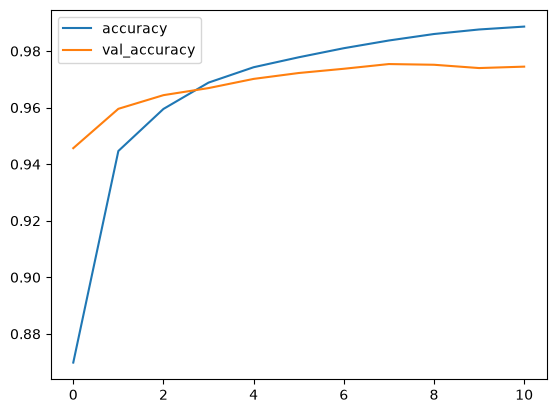

In [11]:
plt.plot(hr.history['accuracy'],label='accuracy')
plt.plot(hr.history['val_accuracy'],label='val_accuracy')
plt.legend()
plt.show()

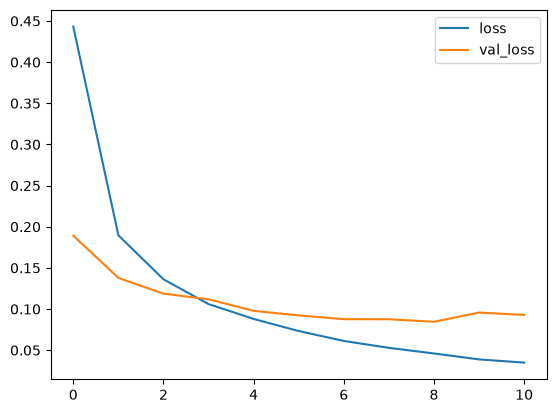

In [12]:
plt.plot(hr.history['loss'], label='loss')
plt.plot(hr.history['val_loss'], label='val_loss')
plt.legend()
plt.show()